In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
# Generate sample data
np.random.seed(42)
x = np.random.normal(loc=50, scale=10, size=500)
y = 2.5 * x + np.random.normal(loc=0, scale=15, size=500)

In [4]:
df = pd.DataFrame({'Feature_X': x, 'Feature_Y': y})

In [5]:
df.head()

,Feature_X,Feature_Y
0,54.967142,151.310517
1,48.617357,150.184642
2,56.476885,120.213700
3,65.230299,171.520285
4,47.658466,109.386527


In [6]:
df.tail()

,Feature_X,Feature_Y
495,55.389100,134.256247
496,39.627538,126.034144
497,48.096613,129.854176
498,41.243817,94.541859
499,36.172003,99.018748


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Feature_X  500 non-null    float64
 1   Feature_Y  500 non-null    float64
dtypes: float64(2)
memory usage: 7.9 KB


In [8]:
df.describe()

,Feature_X,Feature_Y
count,500.000000,500.000000
mean,50.068380,125.648342
std,9.812532,27.613947
min,17.587327,50.962283
25%,42.996926,107.510078
50%,50.127971,125.611116
75%,56.367833,142.064409
max,88.527315,246.765133


In [9]:
# Statistics
mean_x = np.mean(x)
median_x = np.median(x)
variance_x = np.var(x, ddof=1)
correlation = df.corr()

print(f"Mean: {mean_x:.2f} | Median: {median_x:.2f} | Variance: {variance_x:.2f}")
print("\nCorrelation Matrix:\n", correlation)

Mean: 50.07 | Median: 50.13 | Variance: 96.29

Correlation Matrix:
            Feature_X  Feature_Y
Feature_X   1.000000   0.848167
Feature_Y   0.848167   1.000000


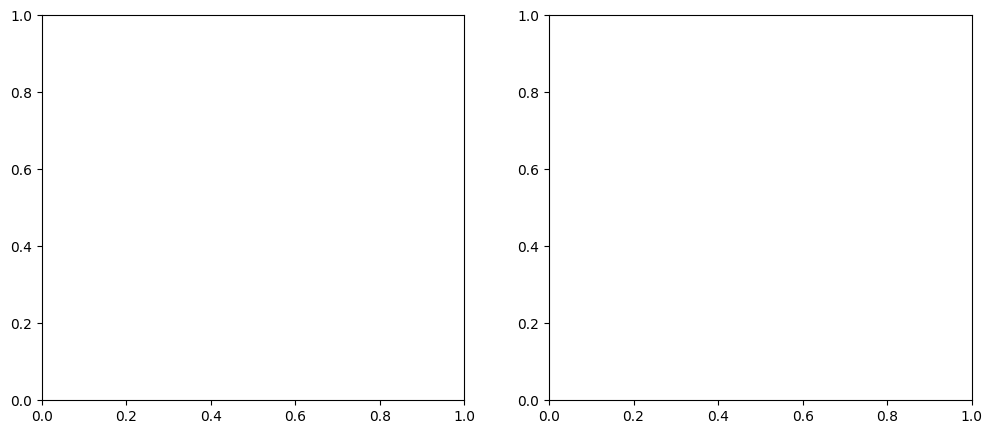

In [10]:
# Visualizations
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

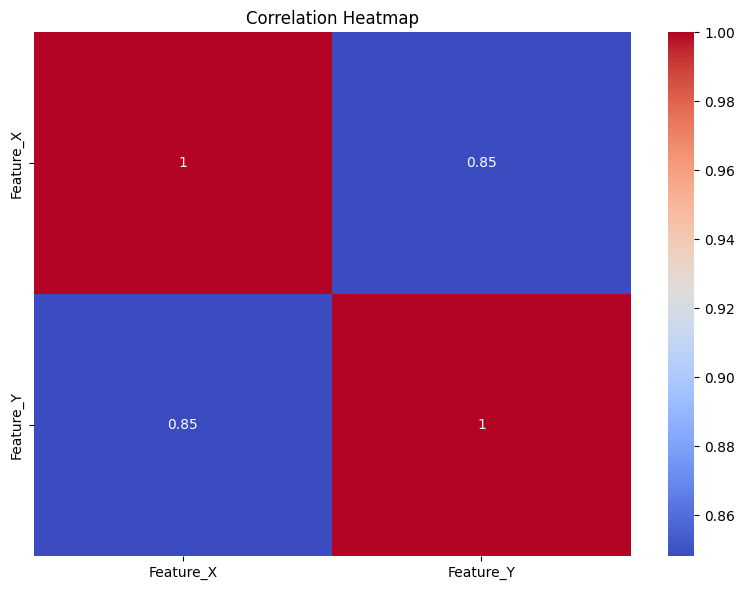

In [13]:
# Correlation Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

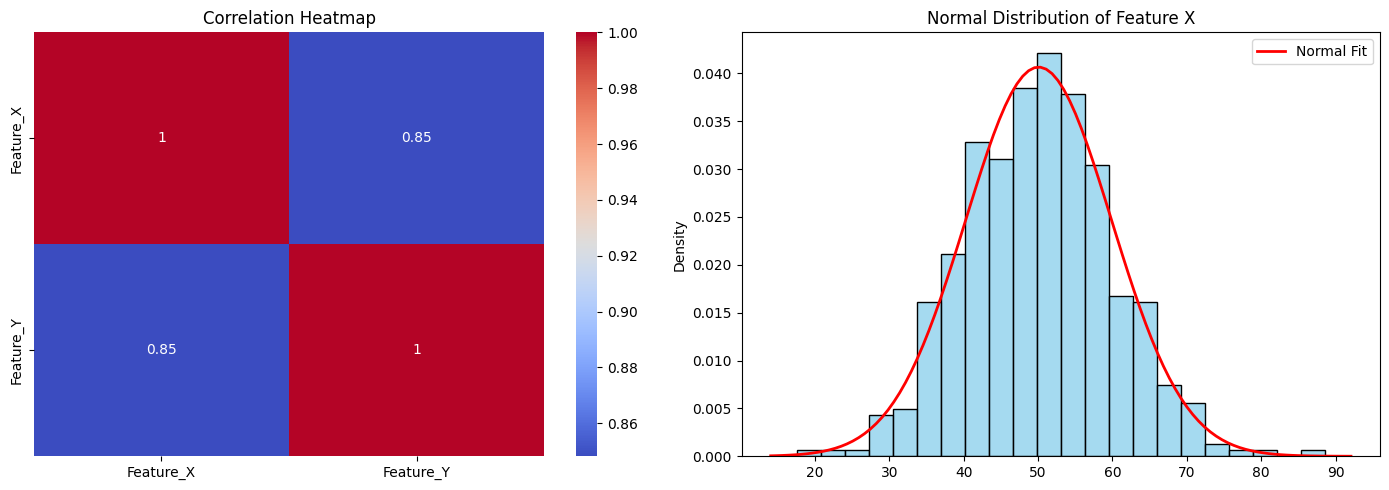

In [15]:
# 1. Initialize the grid
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 2. First plot: Heatmap
sns.heatmap(correlation, annot=True, cmap="coolwarm", ax=axes[0])
axes[0].set_title("Correlation Heatmap")

# 3. Second plot: Distribution
sns.histplot(x, kde=False, stat="density", color="skyblue", ax=axes[1])
xmin, xmax = axes[1].get_xlim()
x_axis = np.linspace(xmin, xmax, 100)
axes[1].plot(
    x_axis,
    stats.norm.pdf(x_axis, mean_x, np.sqrt(variance_x)),
    "r-",
    lw=2,
    label="Normal Fit",
)
axes[1].set_title("Normal Distribution of Feature X")
axes[1].legend()

# 4. Render
plt.tight_layout()
plt.show()